In [22]:
#imports
import numpy as np
import pandas as pd
import matplotlib as mp
import matplotlib.pyplot as plt

In [42]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report

In [4]:
# scikit-learn which consists of 8-by-8 pixels images of 1797 hand-written digits (0-9)

digits = load_digits()

x = digits.data
y = digits.target

print("Dataset Shape:", x.shape)       #8-by-8 pixels values
print("Labels Shape:", y.shape)        #Labels (0-9)

Dataset Shape: (1797, 64)
Labels Shape: (1797,)


In [23]:
#digits dataset
digits = load_digits()

digits

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]]),
 'target': array([0, 1, 2, ..., 8, 9, 8]),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7',
  'pixel_5_0',
  'pixel_5_1',
 

In [25]:
print(digits.DESCR)

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

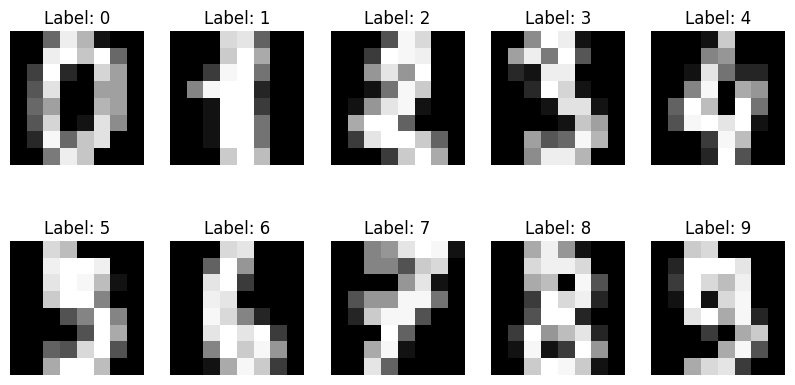

In [5]:
plt.figure(figsize=(10, 5))

for i in range(10):
  plt.subplot(2, 5, i + 1)
  plt.imshow(digits.images[i], cmap="Greys_r")
  plt.title(f"Label: {digits.target[i]}")
  plt.axis("off")

plt.show()

In [15]:
# data for scikit-learn

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size= 0.1, random_state=24)

In [16]:
print('Training Samples:', X_train.shape)
print('Testing Samples:', X_test.shape)
print("y_train.shape:", y_train.shape)
print("y_test.shape :", y_test.shape)

Training Samples: (1617, 64)
Testing Samples: (180, 64)
y_train.shape: (1617,)
y_test.shape : (180,)


In [19]:
# Create KNN Model
knn =   KNeighborsClassifier(n_neighbors= 5)  #by default k = 5

In [53]:
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [52]:
y_pred = knn.predict(X_test)

In [56]:
#Predicts and Expected
predicted = knn.predict(X_test)
expected = y_test

for i in range(20):
    print(f"{i:02d}. predicted={predicted[i]}, expected={expected[i]}")

00. predicted=3, expected=3
01. predicted=7, expected=7
02. predicted=1, expected=1
03. predicted=4, expected=4
04. predicted=6, expected=6
05. predicted=3, expected=3
06. predicted=4, expected=4
07. predicted=5, expected=5
08. predicted=8, expected=8
09. predicted=2, expected=2
10. predicted=4, expected=4
11. predicted=2, expected=2
12. predicted=0, expected=0
13. predicted=3, expected=3
14. predicted=5, expected=5
15. predicted=1, expected=8
16. predicted=7, expected=7
17. predicted=0, expected=0
18. predicted=3, expected=3
19. predicted=6, expected=6


In [59]:
# Number of incorrect predictions
wrong_idx = [i for i, (p, e) in enumerate(zip(predicted, expected)) if p != e]

print("Number of incorrect predictions:", len(wrong_idx))


Number of incorrect predictions: 3


In [60]:
score = knn.score(X_test, y_test)
print(f"KNN Accuracy using score(): {score * 100:.2f}%")


KNN Accuracy using score(): 98.33%


In [63]:
# Confusion Matrix
cm = confusion_matrix(predicted, expected)
cm

array([[15,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0, 17,  0,  0,  0,  0,  0,  0,  1,  0],
       [ 0,  0, 15,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 20,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0, 21,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0, 18,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  0,  0, 16,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 19,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0, 12,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0, 24]])

In [68]:
from sklearn.metrics import ConfusionMatrixDisplay


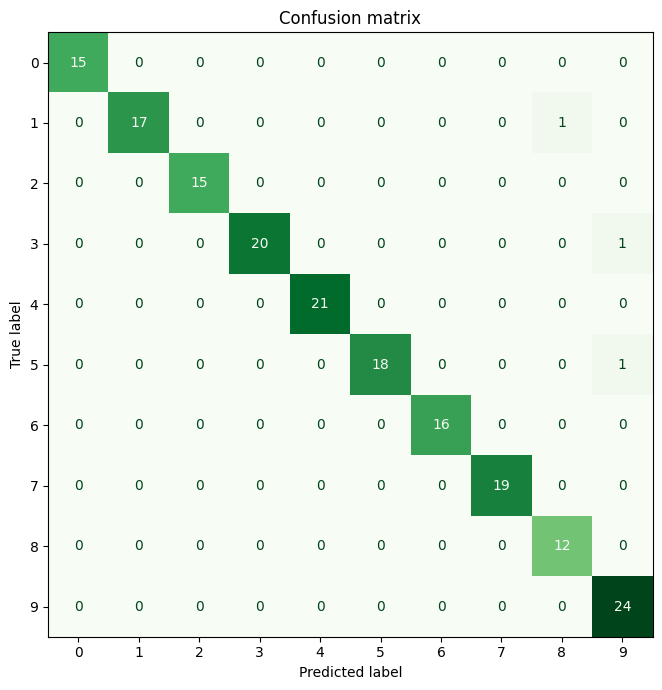

In [73]:
# Show Confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn.classes_)
fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, cmap="Greens", colorbar=False)
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()


In [77]:
# Classification Report
print(classification_report(predicted,expected ))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       1.00      0.94      0.97        18
           2       1.00      1.00      1.00        15
           3       1.00      0.95      0.98        21
           4       1.00      1.00      1.00        21
           5       1.00      0.95      0.97        19
           6       1.00      1.00      1.00        16
           7       1.00      1.00      1.00        19
           8       0.92      1.00      0.96        12
           9       0.92      1.00      0.96        24

    accuracy                           0.98       180
   macro avg       0.98      0.98      0.98       180
weighted avg       0.98      0.98      0.98       180

